In [1]:
import pandas as pd
import numpy as np
import joblib

modelo_pd = joblib.load('../modelo_pd_xgb.pkl')

df = pd.read_csv('../data/accepted_2007_to_2018Q4.csv.gz', low_memory=False)
cols = ['funded_amnt', 'term', 'int_rate', 'grade', 'emp_length',
        'home_ownership', 'annual_inc', 'purpose', 'dti', 'loan_status']
df = df[cols]
df = df[df['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()

# Preparamos features (mismo proceso de siempre)
features = ['funded_amnt', 'term', 'int_rate', 'grade', 'emp_length',
            'home_ownership', 'annual_inc', 'purpose', 'dti']
X_full = df[features].copy().rename(columns={'funded_amnt': 'loan_amnt'})
X_full['term'] = X_full['term'].str.extract(r'(\d+)').astype(float)

emp_map = {'< 1 year': 0, '1 year': 1, '2 years': 2, '3 years': 3, '4 years': 4,
           '5 years': 5, '6 years': 6, '7 years': 7, '8 years': 8, '9 years': 9, '10+ years': 10}
X_full['emp_length'] = X_full['emp_length'].map(emp_map)
grade_map = {'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7}
X_full['grade'] = X_full['grade'].map(grade_map)
X_full = pd.get_dummies(X_full, columns=['home_ownership', 'purpose'], drop_first=True)
X_full['emp_length'] = X_full['emp_length'].fillna(X_full['emp_length'].median())
X_full['dti'] = X_full['dti'].fillna(X_full['dti'].median())

# PD, LGD, EAD (igual que en el Paso 4)
df['PD'] = modelo_pd.predict_proba(X_full)[:, 1]
lgd_dict = {'A': 0.403, 'B': 0.395, 'C': 0.407, 'D': 0.408, 'E': 0.401, 'F': 0.404, 'G': 0.435}
df['LGD'] = df['grade'].map(lgd_dict)
df['EAD'] = df['funded_amnt']

el_baseline = (df['PD'] * df['LGD'] * df['EAD']).sum()
print(f"Expected Loss base (sin estrés): ${el_baseline:,.2f}")

Expected Loss base (sin estrés): $1,687,783,507.57


In [2]:
import matplotlib.pyplot as plt

np.random.seed(42)
n_simulaciones = 10000

# Beta: sensibilidad de la PD a cada punto de suba del desempleo (supuesto, 15%)
beta = 0.15

# Simulamos 10,000 escenarios de shock de desempleo
# Media 0 (el escenario "esperado" es que no cambie nada), desvío 2 puntos porcentuales
shock_desempleo = np.random.normal(loc=0, scale=2, size=n_simulaciones)

# Para cada escenario, el Expected Loss se multiplica por (1 + beta * shock)
# (simplificación: aplicamos el mismo multiplicador a todo el portafolio)
el_simulado = el_baseline * (1 + beta * shock_desempleo)

# No puede haber Expected Loss negativo
el_simulado = np.clip(el_simulado, a_min=0, a_max=None)

print(f"Expected Loss base: ${el_baseline:,.0f}")
print(f"Expected Loss promedio simulado: ${el_simulado.mean():,.0f}")
print(f"Percentil 95 (escenario adverso): ${np.percentile(el_simulado, 95):,.0f}")
print(f"Percentil 99 (escenario muy adverso): ${np.percentile(el_simulado, 99):,.0f}")

Expected Loss base: $1,687,783,508
Expected Loss promedio simulado: $1,686,788,830
Percentil 95 (escenario adverso): $2,519,544,257
Percentil 99 (escenario muy adverso): $2,864,926,530


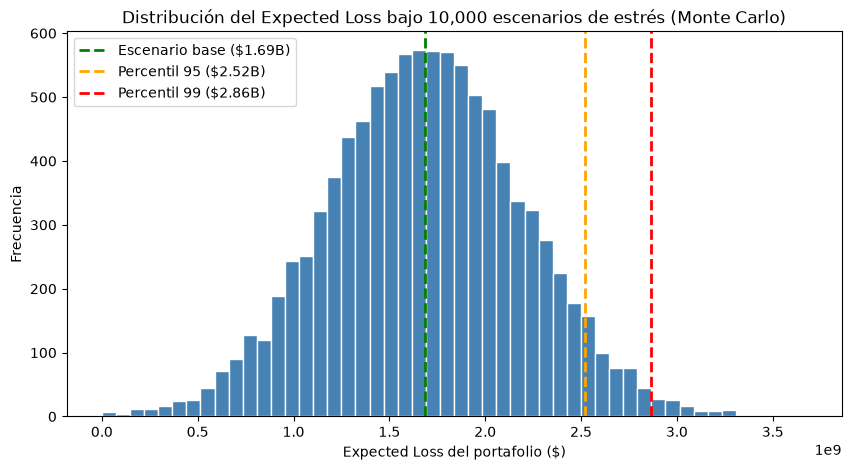

In [3]:
plt.figure(figsize=(10,5))
plt.hist(el_simulado, bins=50, color='steelblue', edgecolor='white')
plt.axvline(el_baseline, color='green', linestyle='--', linewidth=2, label=f'Escenario base (${el_baseline/1e9:.2f}B)')
plt.axvline(np.percentile(el_simulado, 95), color='orange', linestyle='--', linewidth=2, label=f'Percentil 95 (${np.percentile(el_simulado,95)/1e9:.2f}B)')
plt.axvline(np.percentile(el_simulado, 99), color='red', linestyle='--', linewidth=2, label=f'Percentil 99 (${np.percentile(el_simulado,99)/1e9:.2f}B)')
plt.title('Distribución del Expected Loss bajo 10,000 escenarios de estrés (Monte Carlo)')
plt.xlabel('Expected Loss del portafolio ($)')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()